In [1]:
import sys
sys.path.insert(1, '/home/santolam/MyPythonLibrary/MAR-RECAP/libmar/')
import climbasis as climb
from climbasis import *
import domain as dom
import myplot
import numpy.ma as ma
from myplot import *
import obsinfo as obs
from obsinfo import *



In [2]:
plotsDir='/home/santolam/MyPythonLibrary/MAR-RECAP/scripts_paper_on_evaluation_MAR/figures_paper_on_evaluation/'

In [3]:
resultsDir='/home/santolam/MyPythonLibrary/MAR-RECAP/scripts_paper_on_evaluation_MAR/compu_results/'

In [4]:
###
## PYRAMID Salerno
### 

In [5]:
sourceData='/bettik/PROJECTS/pr-regional-climate/santolam/PYRAMID_NETWORK_DATA_v3/'

file_AWS0='AWS0_Z5035_Lvl1.csv'
file_AWS1='AWS1_Z5035_Lvl1.csv'
file_AWS2='AWS2_Z4260_Lvl1.csv'
file_AWS3='AWS3_Z2660_Lvl1.csv'
file_AWS4='AWS4_Z5600_Lvl1.csv'
file_AWS5='AWS5_Z3570_Lvl1.csv'
file_AWSSC='AWSSC_Z7986_Lvl1.csv'
file_CNG='CNG_SNP_Z5700_Lvl1.csv'
file_mon_Pyr='Pyramid_Z5035_lvl2.csv'

# Store filenames in a dictionary for easy looping
files = {
    'AWS0': file_AWS0,
    'AWS1': file_AWS1,
    'AWS2': file_AWS2,
    'AWS3': file_AWS3,
    'AWS4': file_AWS4,
    'AWS5': file_AWS5,
    'AWSSC': file_AWSSC,
    'CNG': file_CNG,
    #'Pyramid': file_mon_Pyr
}
dfs = {}
for name, fname in files.items():
    path = os.path.join(sourceData, fname)
    
    # Read semicolon-delimited CSV
    df = pd.read_csv(path, sep=';')
    
    # Combine into datetime
    df['TIMESTAMP'] = pd.to_datetime(dict(
        year=df['year'],
        month=df['month'],
        day=df['day'],
        hour=df['hour']
    ))
    
    # Set datetime index and drop date columns
    df.set_index('TIMESTAMP', inplace=True)
    df.drop(columns=['year', 'month', 'day', 'hour'], inplace=True)
    
    # Replace physically impossible values (< -100) with NaN
    df[df < -100] = np.nan
    
    # Store
    dfs[name] = df
    
# Optional: unpack for direct access
df_AWS0  = dfs['AWS0']
df_AWS1  = dfs['AWS1']
df_AWS2  = dfs['AWS2']
df_AWS3  = dfs['AWS3']
df_AWS4  = dfs['AWS4']
df_AWS5  = dfs['AWS5']
df_AWSSC = dfs['AWSSC']
df_CNG   = dfs['CNG']
#df_Pyr   = dfs['Pyramid']

# Quick check
print(df_AWS0.head())

#

                       AT   RR     AP    RH    WS  WD
TIMESTAMP                                            
1994-01-01 02:00:00 -11.9  0.0  551.4  25.0  0.00 NaN
1994-01-01 04:00:00 -13.2  0.0  551.0  23.0  0.00 NaN
1994-01-01 06:00:00 -10.5  0.0  551.1  10.0  0.26 NaN
1994-01-01 08:00:00 -10.9  0.0  551.9  17.0  0.00 NaN
1994-01-01 10:00:00  -7.1  0.0  553.1  17.0  5.58 NaN


In [6]:
print(df_AWSSC.head())

                     AT  AP  RH  WS  WD
TIMESTAMP                              
2008-05-01 00:00:00 NaN NaN NaN NaN NaN
2008-05-01 01:00:00 NaN NaN NaN NaN NaN
2008-05-01 02:00:00 NaN NaN NaN NaN NaN
2008-05-01 03:00:00 NaN NaN NaN NaN NaN
2008-05-01 04:00:00 NaN NaN NaN NaN NaN


In [7]:
 #Daily total precipitation (sum of hourly rates)
tt_AWS0_daily = df_AWS0['AT'].resample('D').mean()
tt_AWS1_daily = df_AWS1['AT'].resample('D').mean()
tt_AWS2_daily = df_AWS2['AT'].resample('D').mean()
tt_AWS3_daily = df_AWS3['AT'].resample('D').mean()
tt_AWS4_daily = df_AWS4['AT'].resample('D').mean()
tt_AWS5_daily = df_AWS5['AT'].resample('D').mean()
tt_AWSSC_daily = df_AWSSC['AT'].resample('D').mean()
tt_CNG_daily = df_CNG['AT'].resample('D').mean()


In [8]:
###Coordinates

In [10]:
import pandas as pd
from pyproj import Transformer

# Define the transformer (UTM Zone 45N → WGS84)
transformer = Transformer.from_crs("epsg:32645", "epsg:4326", always_xy=True)

# --- Coordinates conversions (you already have some precomputed) ---
# MN (Mera North)
eastingMN, northingMN = 489885, 3065938
lon_MN, lat_MN = transformer.transform(eastingMN, northingMN)
elev_MN = 5360

# CH (Changri)
lon_CHA3, lat_CHA3, elev_CHA3 = 86.77948450, 27.98336311, 5360

# ML (Merala)
lon_ML, lat_ML, elev_ML = 86.900, 27.735, 5352.008

# KH (Khare)
lon_KH, lat_KH, elev_KH = 86.8776142768303, 27.74424682282522, 4888

# PH (Pheriche)
lon_PH, lat_PH, elev_PH = 86.81972903284355, 27.895048949594884, 4260

# PY (Pyramid)
lon_PY, lat_PY, elev_PY = 86.81296905961787, 27.957821815535848, 5035

# MS (Mera South)
eastingMS, northingMS = 487553.653, 3064704.231
lon_MS, lat_MS = transformer.transform(eastingMS, northingMS)
elev_MS = 6351  # estimated same as MN, if not otherwise specified

# MC (Mera Central; high camp 5770)
eastingMC, northingMC = 488409.424, 3066148.049
lon_MC, lat_MC = transformer.transform(eastingMC, northingMC)
elev_MC = 5770

# --- Define metadata list ---
stations_info_glacioclim = [
    {"ID": "MN", "Name": "Mera Naulek", "Lat": lat_MN, "Lon": lon_MN, "Elev_m": elev_MN, "Timestep": "1h"},
    #{"ID": "CH", "Name": "Changri", "Lat": lat_CH, "Lon": lon_CH, "Elev_m": elev_CH, "Timestep": "1h"},
    {"ID": "ML", "Name": "Mera La", "Lat": lat_ML, "Lon": lon_ML, "Elev_m": elev_ML, "Timestep": "1h"},
    {"ID": "KH", "Name": "Khare", "Lat": lat_KH, "Lon": lon_KH, "Elev_m": elev_KH, "Timestep": "1h"},
    {"ID": "PH", "Name": "Pheriche", "Lat": lat_PH, "Lon": lon_PH, "Elev_m": elev_PH, "Timestep": "1h"},
    {"ID": "PY", "Name": "Pyramid", "Lat": lat_PY, "Lon": lon_PY, "Elev_m": elev_PY, "Timestep": "1h"},
    {"ID": "MS", "Name": "Mera Summir", "Lat": lat_MS, "Lon": lon_MS, "Elev_m": elev_MS, "Timestep": "1h"},
    {"ID": "MC", "Name": "Mera Camp 5770", "Lat": lat_MC, "Lon": lon_MC, "Elev_m": elev_MC, "Timestep": "1h"},
   # {"ID": "PYG", "Name": "Pyramid-AWS", "Lat": lat_PYG, "Lon": lon_PYG, "Elev_m": elev_PYG, "Timestep": "1h"},
    {"ID": "CHA3", "Name": "CHA3", "Lat": lat_CHA3, "Lon": lon_CHA3, "Elev_m": elev_CHA3, "Timestep": "1h"},
]


# --- Create DataFrame ---
df_stations_glacioclim = pd.DataFrame(stations_info_glacioclim)

# Display neatly
print(df_stations_glacioclim.to_string(index=False, justify='center', col_space=12))


     ID           Name           Lat          Lon        Elev_m      Timestep  
      MN        Mera Naulek  27.717723    86.897390     5360.000        1h     
      ML            Mera La  27.735000    86.900000     5352.008        1h     
      KH              Khare  27.744247    86.877614     4888.000        1h     
      PH           Pheriche  27.895049    86.819729     4260.000        1h     
      PY            Pyramid  27.957822    86.812969     5035.000        1h     
      MS        Mera Summir  27.706566    86.873753     6351.000        1h     
      MC     Mera Camp 5770  27.719608    86.882420     5770.000        1h     
    CHA3               CHA3  27.983363    86.779484     5360.000        1h     


In [11]:
# Station coordinates and elevations
lat_AWSSC, lon_AWSSC, elev_AWSSC = 27.98, 86.76, 7986
lat_CNG, lon_CNG, elev_CNG = 27.96, 86.93, 5700
lat_AWS0, lon_AWS0, elev_AWS0 = 27.96, 86.81, 5035
lat_AWS1, lon_AWS1, elev_AWS1 = 27.96, 86.81, 5035
lat_AWS2, lon_AWS2, elev_AWS2 = 27.90, 86.82, 4260
lat_AWS3, lon_AWS3, elev_AWS3 = 27.70, 86.72, 2660
lat_AWS4, lon_AWS4, elev_AWS4 = 27.99, 86.83, 5600
lat_AWS5, lon_AWS5, elev_AWS5 = 27.80, 86.71, 3570
lat_Pyr, lon_Pyr, elev_Pyr = 27.96, 86.81, 5035

# Metadata list using the variable names
stations_info_salerno = [
    {"ID": "AWSSC", "Name": "South Col", "Lat": lat_AWSSC, "Lon": lon_AWSSC, "Elev_m": elev_AWSSC, "Timestep": "1h"},
    {"ID": "CNG_SNP", "Name": "Changri Nup", "Lat": lat_CNG, "Lon": lon_CNG, "Elev_m": elev_CNG, "Timestep": "1h"},
    {"ID": "AWS0", "Name": "Pyramid", "Lat": lat_AWS0, "Lon": lon_AWS0, "Elev_m": elev_AWS0, "Timestep": "1h"},
    {"ID": "AWS1", "Name": "Pyramid", "Lat": lat_AWS1, "Lon": lon_AWS1, "Elev_m": elev_AWS1, "Timestep": "1h"},
    {"ID": "AWS2", "Name": "Pheriche", "Lat": lat_AWS2, "Lon": lon_AWS2, "Elev_m": elev_AWS2, "Timestep": "1h"},
    {"ID": "AWS3", "Name": "Lukla", "Lat": lat_AWS3, "Lon": lon_AWS3, "Elev_m": elev_AWS3, "Timestep": "1h"},
    {"ID": "AWS4", "Name": "Kala Patthar", "Lat": lat_AWS4, "Lon": lon_AWS4, "Elev_m": elev_AWS4, "Timestep": "1h"},
    {"ID": "AWS5", "Name": "Namche", "Lat": lat_AWS5, "Lon": lon_AWS5, "Elev_m": elev_AWS5, "Timestep": "1h"},
    #{"ID": "PYmon", "Name": "Pyramid (monthly)", "Lat": lat_Pyr, "Lon": lon_Pyr, "Elev_m": elev_Pyr, "Timestep": "1month"},
]
# Create DataFrame
df_stations_salerno = pd.DataFrame(stations_info_salerno)

# Display
print(df_stations_salerno)

        ID          Name    Lat    Lon  Elev_m Timestep
0    AWSSC     South Col  27.98  86.76    7986       1h
1  CNG_SNP   Changri Nup  27.96  86.93    5700       1h
2     AWS0       Pyramid  27.96  86.81    5035       1h
3     AWS1       Pyramid  27.96  86.81    5035       1h
4     AWS2      Pheriche  27.90  86.82    4260       1h
5     AWS3         Lukla  27.70  86.72    2660       1h
6     AWS4  Kala Patthar  27.99  86.83    5600       1h
7     AWS5        Namche  27.80  86.71    3570       1h


In [12]:
# NatGeo Everest AWS coordinates
#Phortse Base Camp Camp II South Col Balcony  Table1 Matthews
#Latitude (°N) 27.8456 27.9952 27.9810 27.9719 27.9826
#lat_phort,lat_bc,lat_c2,lat_sc,lat_bish=27.8456, 27.9952, 27.9810, 27.9719, 27.9826
#Longitude (°E) 86.7472 86.8406 86.9023 86.9295 86.9292
#lon_phort,lon_bc,lon_c2,lon_sc,lon_bish=86.7472, 86.8406, 86.9023 ,86.9295 ,86.9292
#Elevation (m MSL) 3,810 5,315 6,464 7,945 8,430
#elev_phort,elev_bc,elev_c2,elev_sc,elev_bish=3810, 5315 ,6464 ,7945, 8430
# BASE CAMP AWS (27.9952 N, 86.8406 E, 5315 M ASL)
lat_bc, lon_bc, elev_bc = 27.9952, 86.8406, 5315

# CAMP II AWS (27.9810 N, 86.9023 E, 6464 M ASL)
lat_c2, lon_c2, elev_c2 = 27.9810, 86.9023, 6464 

# PHORTSE AWS (27.8456 N, 86.7472 E, 3810 M ASL)
lat_phort, lon_phort, elev_phort = 27.8456, 86.7472, 3810 

# BISHOP ROCK AWS (27.9735 N, 86.9308 E, 8810 M ASL)
lat_bish, lon_bish, elev_bish = 27.9735, 86.9308, 8810 

# MT. EVEREST SOUTH COL AWS (27.9719 N, 86.9295 E, 7945 M ASL)
lat_sc, lon_sc, elev_sc = 27.9719, 86.9295, 7945


# Define metadata for Everest AWS network using variables
stations_info_everest = [
    {"ID": "bc", "Name": "Base Camp AWS", "Lat": lat_bc, "Lon": lon_bc, "Elev_m": elev_bc},
    {"ID": "c2", "Name": "Camp II AWS", "Lat": lat_c2, "Lon": lon_c2, "Elev_m": elev_c2},
    {"ID": "phort", "Name": "Phortse AWS", "Lat": lat_phort, "Lon": lon_phort, "Elev_m": elev_phort},
    {"ID": "bish", "Name": "Bishop Rock AWS", "Lat": lat_bish, "Lon": lon_bish, "Elev_m": elev_bish},
    {"ID": "sc", "Name": "Mt. Everest South Col AWS", "Lat": lat_sc, "Lon": lon_sc, "Elev_m": elev_sc},
]

# Create DataFrame
df_everest_stations = pd.DataFrame(stations_info_everest)

# Display
print(df_everest_stations)


      ID                       Name      Lat      Lon  Elev_m
0     bc              Base Camp AWS  27.9952  86.8406    5315
1     c2                Camp II AWS  27.9810  86.9023    6464
2  phort                Phortse AWS  27.8456  86.7472    3810
3   bish            Bishop Rock AWS  27.9735  86.9308    8810
4     sc  Mt. Everest South Col AWS  27.9719  86.9295    7945


In [13]:
# --- Merge all station metadata into one unified dictionary ---
stations_all = {}

# Add Salerno AWS
for sta in stations_info_salerno:
    stations_all[sta["ID"]] = (sta["Lat"], sta["Lon"], "SalernoAWS")
# Check summary
print(f"Total stations merged: {len(stations_all)}")
print(stations_all.keys())

Total stations merged: 8
dict_keys(['AWSSC', 'CNG_SNP', 'AWS0', 'AWS1', 'AWS2', 'AWS3', 'AWS4', 'AWS5'])


In [14]:
import matplotlib.pyplot as plt

stations_tt_daily_salerno = {
    "AWS0": tt_AWS0_daily,
    "AWS1": tt_AWS1_daily,
    "AWS2": tt_AWS2_daily,
    "AWS3": tt_AWS3_daily,
    "AWS4": tt_AWS4_daily,
    "AWS5": tt_AWS5_daily,
}



In [21]:
stations_tt_daily_salerno#.item()

{'AWS0': TIMESTAMP
 1994-01-01    -9.310000
 1994-01-02    -7.485833
 1994-01-03   -10.183333
 1994-01-04   -10.425833
 1994-01-05   -12.491667
                 ...    
 2005-12-27    -9.500833
 2005-12-28    -8.150833
 2005-12-29    -7.525000
 2005-12-30    -5.117500
 2005-12-31    -3.567500
 Freq: D, Name: AT, Length: 4383, dtype: float64,
 'AWS1': TIMESTAMP
 2000-01-01         NaN
 2000-01-02         NaN
 2000-01-03         NaN
 2000-01-04         NaN
 2000-01-05         NaN
                 ...   
 2023-12-27   -5.238750
 2023-12-28   -5.407500
 2023-12-29   -6.510000
 2023-12-30   -8.961250
 2023-12-31   -9.078333
 Freq: D, Name: AT, Length: 8766, dtype: float64,
 'AWS2': TIMESTAMP
 2001-01-01         NaN
 2001-01-02         NaN
 2001-01-03         NaN
 2001-01-04         NaN
 2001-01-05         NaN
                 ...   
 2023-12-27   -5.693333
 2023-12-28   -7.352917
 2023-12-29   -5.938750
 2023-12-30   -6.960000
 2023-12-31   -7.212917
 Freq: D, Name: AT, Length: 8400, dtype:

 Saved: /home/santolam/MyPythonLibrary/MAR-RECAP/scripts_paper_on_evaluation_MAR/figures_paper_on_evaluation/support_FIGSX_timeseries_daily_tas.salerno.png


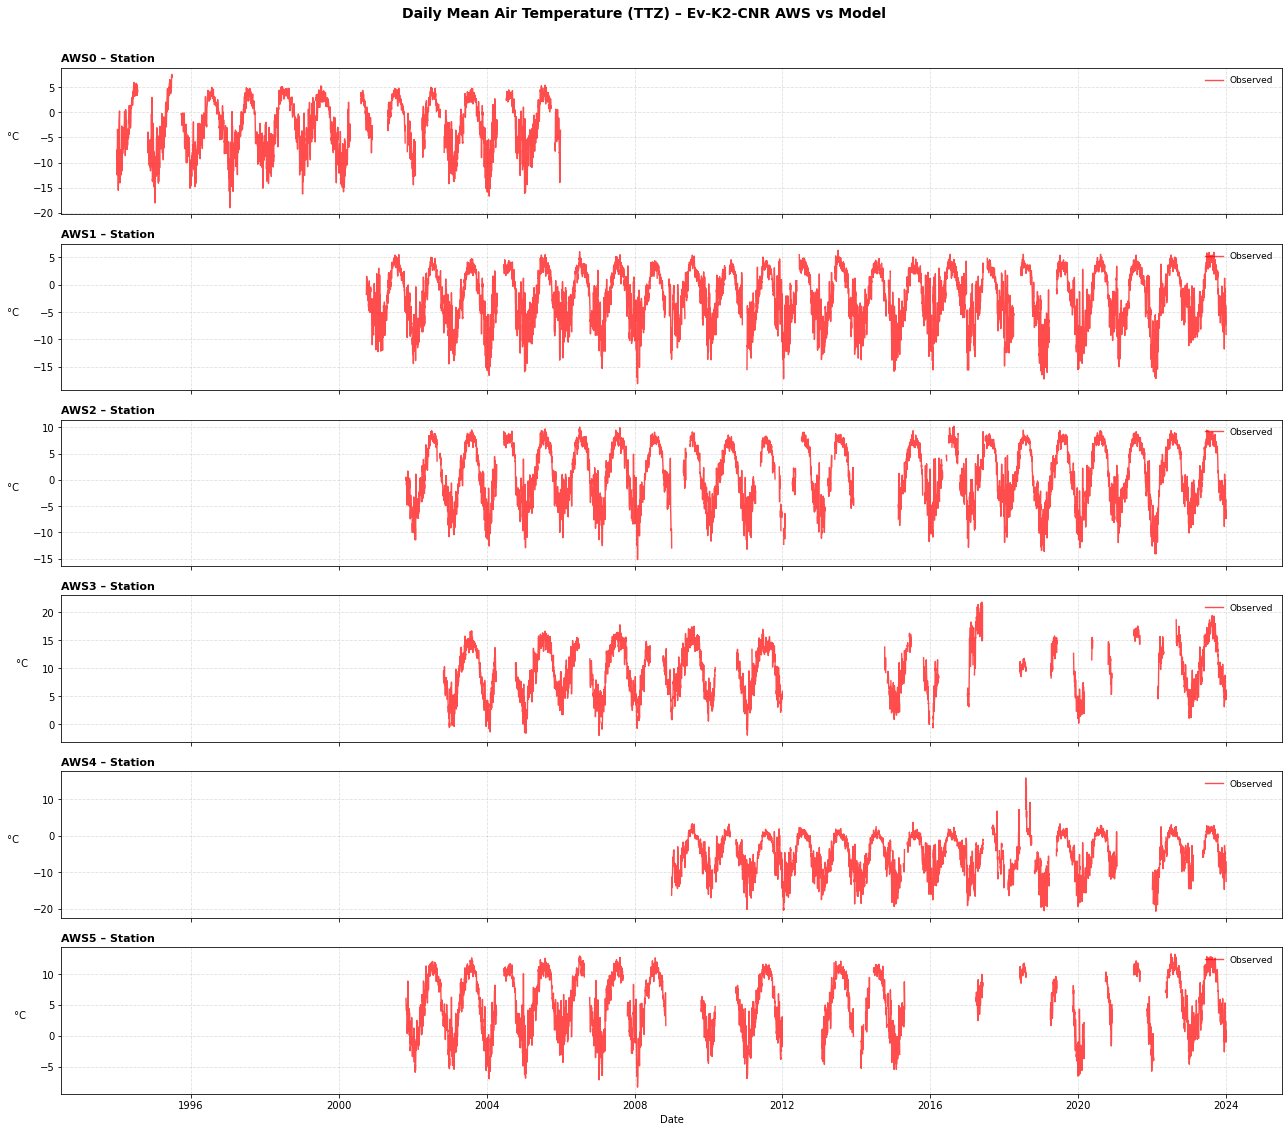

In [22]:
# --- Create subplots (one per station) ---
fig, axes = plt.subplots(len(stations_tt_daily_salerno), 1, figsize=(18, 16), sharex=True)

# --- Plot each station ---
for ax, (name, obs_series) in zip(axes, stations_tt_daily_salerno.items()):
    # Observed daily temperature (line)
    ax.plot(obs_series.index, obs_series.values, color='red', lw=1.4, alpha=0.7, label="Observed")

      # Style + Title
    ax.set_ylabel("°C", rotation=0, labelpad=20)
    ax.set_title(f"{name} – Station",
                 loc='left', fontsize=11, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.legend(frameon=False, loc='upper right', fontsize=9)

# Shared labels and figure title
axes[-1].set_xlabel("Date")
fig.suptitle("Daily Mean Air Temperature (TTZ) – Ev-K2-CNR AWS vs Model",
             fontsize=14, fontweight='bold')

plt.tight_layout(rect=[0, 0, 1, 0.97])

plotname = f"support_FIGSX_timeseries_daily_tas.salerno"
plt.savefig(f"{plotsDir}{plotname}.png", bbox_inches="tight", dpi=300)
print(f" Saved: {plotsDir}{plotname}.png")

plt.show()


In [24]:
idate_AWS0 = str(tt_AWS0_daily.index[0].date())
fdate_AWS0 = str(tt_AWS0_daily.index[-1].date())
idate_AWS1 = str(tt_AWS1_daily.index[0].date())
fdate_AWS1 = str(tt_AWS1_daily.index[-1].date())
idate_AWS2 = str(tt_AWS2_daily.index[0].date())
fdate_AWS2 = str(tt_AWS2_daily.index[-1].date())
idate_AWS3 = str(tt_AWS3_daily.index[0].date())
fdate_AWS3 = str(tt_AWS3_daily.index[-1].date())
idate_AWS4 = str(tt_AWS4_daily.index[0].date())
fdate_AWS4 = str(tt_AWS4_daily.index[-1].date())
idate_AWS5 = str(tt_AWS5_daily.index[0].date())
fdate_AWS5 = str(tt_AWS5_daily.index[-1].date())
idate_CNG = str(tt_CNG_daily.index[0].date())
fdate_CNG = str(tt_CNG_daily.index[-1].date())


In [25]:
date_ranges = {
    "AWS0": f"{idate_AWS0} to {fdate_AWS0}",
    "AWS1": f"{idate_AWS1} to {fdate_AWS1}",
    "AWS2": f"{idate_AWS2} to {fdate_AWS2}",
    "AWS3": f"{idate_AWS3} to {fdate_AWS3}",
    "AWS4": f"{idate_AWS4} to {fdate_AWS4}",
    "AWS5": f"{idate_AWS5} to {fdate_AWS5}"
}

In [28]:
stations_tt_daily_salerno

{'AWS0': TIMESTAMP
 1994-01-01    -9.310000
 1994-01-02    -7.485833
 1994-01-03   -10.183333
 1994-01-04   -10.425833
 1994-01-05   -12.491667
                 ...    
 2005-12-27    -9.500833
 2005-12-28    -8.150833
 2005-12-29    -7.525000
 2005-12-30    -5.117500
 2005-12-31    -3.567500
 Freq: D, Name: AT, Length: 4383, dtype: float64,
 'AWS1': TIMESTAMP
 2000-01-01         NaN
 2000-01-02         NaN
 2000-01-03         NaN
 2000-01-04         NaN
 2000-01-05         NaN
                 ...   
 2023-12-27   -5.238750
 2023-12-28   -5.407500
 2023-12-29   -6.510000
 2023-12-30   -8.961250
 2023-12-31   -9.078333
 Freq: D, Name: AT, Length: 8766, dtype: float64,
 'AWS2': TIMESTAMP
 2001-01-01         NaN
 2001-01-02         NaN
 2001-01-03         NaN
 2001-01-04         NaN
 2001-01-05         NaN
                 ...   
 2023-12-27   -5.693333
 2023-12-28   -7.352917
 2023-12-29   -5.938750
 2023-12-30   -6.960000
 2023-12-31   -7.212917
 Freq: D, Name: AT, Length: 8400, dtype:

In [30]:

# =========================================================
# Function: seasonal mean ± std
# =========================================================

def seasonal_stats(series):

    seasons = {
        "DJFM": [12, 1, 2, 3],
        "AM": [4, 5],
        "JJAS": [6, 7, 8, 9],
        "ON": [10, 11]
    }

    stats = {}

    for season, months in seasons.items():

        data = series[series.index.month.isin(months)]

        mean = data.mean()
        std = data.std()

        stats[season] = f"{mean:.2f} ± {std:.2f}"

    return stats



# =========================================================
# Build table
# =========================================================

rows = []

for station in stations_tt_daily_salerno.keys():

    # Observation series
    obs = stations_tt_daily_salerno[station]#.to_pandas()

    # Seasonal climatology
    clim_obs = seasonal_stats(obs)

    # Add row
    rows.append({

        "Station": station,

        "DJFM": clim_obs["DJFM"],

        "AM": clim_obs["AM"],

        "JJAS": clim_obs["JJAS"],

        "ON": clim_obs["ON"],
         "Period": date_ranges[station],
    })

# =========================================================
# Create DataFrame
# =========================================================

df_clim = pd.DataFrame(rows)

print(df_clim)

# =========================================================
# Save CSV
# =========================================================

outfile = f"{resultsDir}/seasonal_climatology_TTZ_salerno.csv"

df_clim.to_csv(outfile, index=False)

print(f"\nSaved: {outfile}")

  Station           DJFM            AM          JJAS            ON  \
0    AWS0   -7.69 ± 3.58  -2.23 ± 2.94   2.82 ± 1.50  -3.69 ± 2.85   
1    AWS1   -6.81 ± 3.78  -2.52 ± 2.44   2.82 ± 1.29  -2.94 ± 2.74   
2    AWS2   -4.84 ± 3.36   1.58 ± 2.37   7.07 ± 1.22  -0.41 ± 2.96   
3    AWS3    5.69 ± 3.20  12.25 ± 2.74  14.54 ± 1.70   9.16 ± 2.54   
4    AWS4  -10.43 ± 3.87  -5.54 ± 2.75   0.14 ± 1.61  -5.66 ± 2.92   
5    AWS5    0.09 ± 2.91   6.26 ± 2.24  10.41 ± 1.06   4.04 ± 2.56   

                     Period  
0  1994-01-01 to 2005-12-31  
1  2000-01-01 to 2023-12-31  
2  2001-01-01 to 2023-12-31  
3  2002-01-01 to 2023-12-31  
4  2009-01-01 to 2023-12-31  
5  2001-01-01 to 2023-12-31  

Saved: /home/santolam/MyPythonLibrary/MAR-RECAP/scripts_paper_on_evaluation_MAR/compu_results//seasonal_climatology_TTZ_salerno.csv
